In [44]:
# 1. Imports and configuration

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats


from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer


import joblib
from pathlib import Path

from sklearn import set_config
set_config(display='diagram')



random_state = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Data Loading and Validation

Load the dataset, inspect its structure, and verify data quality before
performing preprocessing or model training.

In [45]:
# import Dataset
df = pd.read_csv('/kaggle/input/datasets/mirichoi0218/insurance/insurance.csv')

# Inspection of the dataset
print("Dataset shape:", df.shape)

display(df.head(10))
display(df.info())
display(df.describe(include="all").T)

Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,"16,884.924"
1,18,male,33.770,1,no,southeast,"1,725.552"
2,28,male,33.000,3,no,southeast,"4,449.462"
3,33,male,22.705,0,no,northwest,"21,984.471"
4,32,male,28.880,0,no,northwest,"3,866.855"
5,31,female,25.740,0,no,southeast,"3,756.622"
6,46,female,33.440,1,no,southeast,"8,240.590"
7,37,female,27.740,3,no,northwest,"7,281.506"
8,37,male,29.830,2,no,northeast,"6,406.411"
9,60,female,25.840,0,no,northwest,"28,923.137"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"1,338.000",NaN,NaN,NaN,39.207,14.050,18.000,27.000,39.000,51.000,64.000
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,"1,338.000",NaN,NaN,NaN,30.663,6.098,15.960,26.296,30.400,34.694,53.130
children,"1,338.000",NaN,NaN,NaN,1.095,1.205,0.000,0.000,1.000,2.000,5.000
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,"1,338.000",NaN,NaN,NaN,"13,270.422","12,110.011","1,121.874","4,740.287","9,382.033","16,639.913","63,770.428"


In [46]:
# Checking data quality
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

print("\nColumn data types:")
print(df.dtypes)

print("\nTarget variable distribution:")
display(df["charges"].describe())

Duplicate rows: 1

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Column data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Target variable distribution:


count    1,338.000
mean    13,270.422
std     12,110.011
min      1,121.874
25%      4,740.287
50%      9,382.033
75%     16,639.913
max     63,770.428
Name: charges, dtype: float64

## 2. Exploratory Data Analysis (EDA)

The objective of EDA is to understand the distribution of insurance
charges, identify potential outliers, examine relationships between
predictor variables and the target, and identify patterns that may
influence model selection.

<Axes: xlabel='charges', ylabel='Count'>

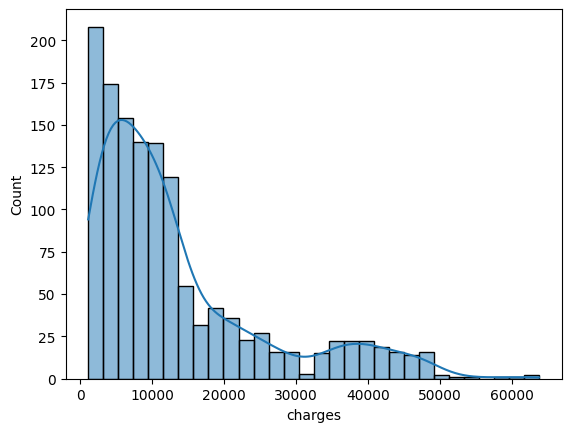

In [47]:
# Visualize the distribution
sns.histplot(data=df, x="charges", kde=True)

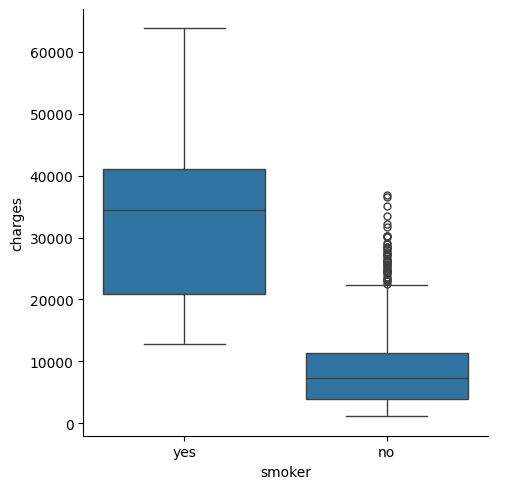

In [48]:
sns.catplot(x=df['smoker'],y=df['charges'],kind='box')

<Axes: xlabel='age', ylabel='charges'>

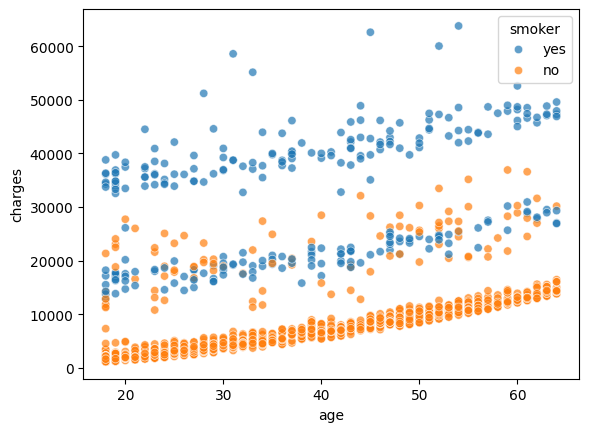

In [49]:
sns.scatterplot(x=df['age'],y=df['charges'],hue=df['smoker'],alpha=0.7)

<Axes: xlabel='bmi', ylabel='charges'>

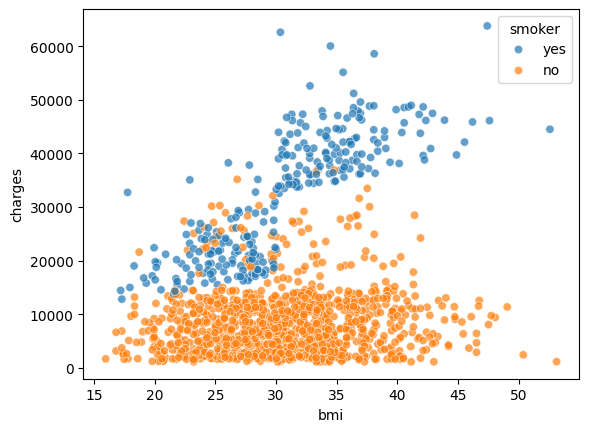

In [50]:
sns.scatterplot(x=df['bmi'],y=df['charges'],hue=df['smoker'],alpha=0.7)

In [51]:
!pip install -q fg-data-profiling

In [52]:
import data_profiling
from data_profiling import ProfileReport
prof = ProfileReport(df)
prof

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:00<00:00, 15725.83it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## 3. Data Quality and Preparation

Remove duplicate records, validate the target and feature columns, and
separate the input features from the target variable.

In [53]:
# Define expected columns
expected_columns = {
    "age", "sex", "bmi", "children",
    "smoker", "region", "charges"
}

# Validate schema
assert set(df.columns) == expected_columns, (
    f"Unexpected columns: {df.columns.tolist()}"
)

# Remove duplicate records
df = df.drop_duplicates().copy()

# Validate data quality
assert df.isnull().sum().sum() == 0, "Missing values detected."
assert (df["charges"] >= 0).all(), "Negative charges detected."

# Separate features and target
X = df.drop(columns="charges")
y = df["charges"]

print("Cleaned dataset shape:", df.shape)
print("Features:", X.columns.tolist())
print("Target:", y.name)
print("Duplicates remaining:", df.duplicated().sum())

Cleaned dataset shape: (1337, 7)
Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target: charges
Duplicates remaining: 0


## 4. Train-Test Split

Split the dataset before fitting any preprocessing transformations to
prevent data leakage and reserve unseen data for evaluation.

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1069, 6)
Testing features: (268, 6)
Training target: (1069,)
Testing target: (268,)


## 5. Preprocessing Pipeline

Pass numeric features through unchanged and one-hot encode categorical
features. Fit these transformations only on training data.

In [55]:
numeric_features = ["age", "bmi", "children"]

categorical_features = ["sex", "smoker", "region"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]) 

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [56]:
X_train_transformed = preprocessor.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_transformed.shape)
print("Preprocessing completed successfully.")

Original training shape: (1069, 6)
Transformed training shape: (1069, 8)
Preprocessing completed successfully.


## 6. Baseline Model

Establish a reference performance using a DummyRegressor that always
predicts the mean insurance charge from the training data.

In [57]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DummyRegressor(strategy="mean"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = root_mean_squared_error(y_test, baseline_predictions)
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE:  {baseline_mae:,.2f}")
print(f"Baseline RMSE: {baseline_rmse:,.2f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline MAE:  9,861.80
Baseline RMSE: 13,612.43
Baseline R²:   -0.0084


## 7. Model tuning with: Random Forest Regressor

Train the selected Random Forest using the hyperparameters identified
during cross-validation. All preprocessing is encapsulated in the pipeline.

In [58]:
final_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

tuning_model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        max_depth=5,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=random_state,
        n_jobs=-1
    ))
])

tuning_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [59]:
# Evaluating the trained model
predictions = tuning_model.predict(X_test)

tuning_mae = mean_absolute_error(y_test, predictions)
tuning_rmse = root_mean_squared_error(y_test, predictions)
tuning_r2 = r2_score(y_test, predictions)

print(f"Test MAE:  {tuning_mae:,.2f}")
print(f"Test RMSE: {tuning_rmse:,.2f}")
print(f"Test R²:   {tuning_r2:.4f}")

Test MAE:  2,384.14
Test RMSE: 4,203.37
Test R²:   0.9038


In [60]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [61]:
cv_results = cross_validate(
    tuning_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Mean": [
        -cv_results["test_mae"].mean(),
        -cv_results["test_rmse"].mean(),
        cv_results["test_r2"].mean()
    ],
    "Std Dev": [
        cv_results["test_mae"].std(),
        cv_results["test_rmse"].std(),
        cv_results["test_r2"].std()
    ]
})

display(cv_summary.round(4))

,Metric,Mean,Std Dev
0,MAE,"2,547.043",70.277
1,RMSE,"4,579.474",193.169
2,R²,0.844,0.025


In [62]:
# checking with the log-transformed target variable

# Model A: Original target
original_target_model = tuning_model

# Model B: Log-transformed target
log_target_model = TransformedTargetRegressor(
    regressor=tuning_model,
    func=np.log1p,
    inverse_func=np.expm1
)

# Evaluate both using identical CV splits
models = {
    "Original Target": original_target_model,
    "Log Transformed Target": log_target_model
}

target_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    target_results.append({
        "Model": name,
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV R2": scores["test_r2"].mean()
    })

target_comparison = pd.DataFrame(target_results)

display(target_comparison.round(3))

,Model,CV MAE,CV RMSE,CV R2
0,Original Target,"2,547.043","4,579.474",0.844
1,Log Transformed Target,"2,110.816","4,580.189",0.844


In [63]:
# Evaluate each fold separately

original_scores = cross_validate(
    tuning_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

log_scores = cross_validate(
    log_target_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

fold_comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "Original Target MAE": -original_scores["test_score"],
    "Log Target MAE": -log_scores["test_score"]
})

fold_comparison["Improvement"] = (
    fold_comparison["Original Target MAE"]
    - fold_comparison["Log Target MAE"]
)

display(fold_comparison.round(2))

,Fold,Original Target MAE,Log Target MAE,Improvement
0,1,"2,642.000","2,216.410",425.590
1,2,"2,569.590","2,023.170",546.430
2,3,"2,468.250","1,956.470",511.780
3,4,"2,591.760","2,258.350",333.410
4,5,"2,463.610","2,099.680",363.930


We can see there is an improvement in our log_transformed target model. So we are going to test the imporvement, if we find enough evidence we will use that as our final model.

In [64]:
# Train the selected transformed-target model
log_target_model.fit(X_train, y_train)

# Generate predictions in original charge units
log_predictions = log_target_model.predict(X_test)

# Calculate evaluation metrics
log_test_mae = mean_absolute_error(y_test, log_predictions)

log_test_rmse = root_mean_squared_error(y_test,log_predictions)

log_test_r2 = r2_score(y_test, log_predictions)

print(f"Test MAE:  {log_test_mae:,.2f}")
print(f"Test RMSE: {log_test_rmse:,.2f}")
print(f"Test R²:   {log_test_r2:.4f}")

Test MAE:  1,937.33
Test RMSE: 4,186.49
Test R²:   0.9046


In [ ]:
log_cv_scores = cross_validate(
    log_target_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

log_cv_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Mean": [
        -log_cv_scores["test_mae"].mean(),
        -log_cv_scores["test_rmse"].mean(),
        log_cv_scores["test_r2"].mean()
    ],
    "Std Dev": [
        log_cv_scores["test_mae"].std(),
        log_cv_scores["test_rmse"].std(),
        log_cv_scores["test_r2"].std()
    ]
})

display(log_cv_summary.round(3))

In [65]:
# after the model was fitted we saw an imporvement in Test MAE, RMSE and R2 score comparitively.

compare = pd.DataFrame({
    "Metrics": ["Test MAE:","Test RMSE:","Test R2 Score:"],
    "Tuned_Decision_Tree":[tuning_mae,tuning_rmse,tuning_r2],
    "Log_transformed_target_Tuned_Decision_Tree":[log_test_mae,log_test_rmse,log_test_r2],
})

compare['Improvement'] = compare["Tuned_Decision_Tree"] - compare["Log_transformed_target_Tuned_Decision_Tree"]

# A negative r2 score means improvement towards good.

compare

,Metrics,Tuned_Decision_Tree,Log_transformed_target_Tuned_Decision_Tree,Improvement
0,Test MAE:,"2,384.139","1,937.333",446.806
1,Test RMSE:,"4,203.368","4,186.490",16.878
2,Test R2 Score:,0.904,0.905,-0.001


In [66]:
# further we are diagnosing the improvement in the actual vx predicted and predicted vs residual,
# respectively with smoker

diagnostics_log = X_test.copy()

diagnostics_log["actual"] = y_test
diagnostics_log["predicted"] = log_predictions

diagnostics_log["residual"] = (
    diagnostics_log["actual"]
    - diagnostics_log["predicted"]
)

diagnostics_log["absolute_error"] = (
    diagnostics_log["residual"].abs()
)

smoker_diagnostics_log = (
    diagnostics_log
    .groupby("smoker")
    .agg(
        count=("actual", "count"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean"),
        RMSE=("residual", lambda x: np.sqrt(np.mean(x**2)))
    )
)

display(smoker_diagnostics_log.round(2))

,count,actual_mean,predicted_mean,MAE,mean_residual,RMSE
smoker,,,,,,
no,208,"8,202.990","7,786.980","1,769.490",416.020,"3,995.480"
yes,60,"35,311.260","34,423.110","2,519.180",888.150,"4,790.030"


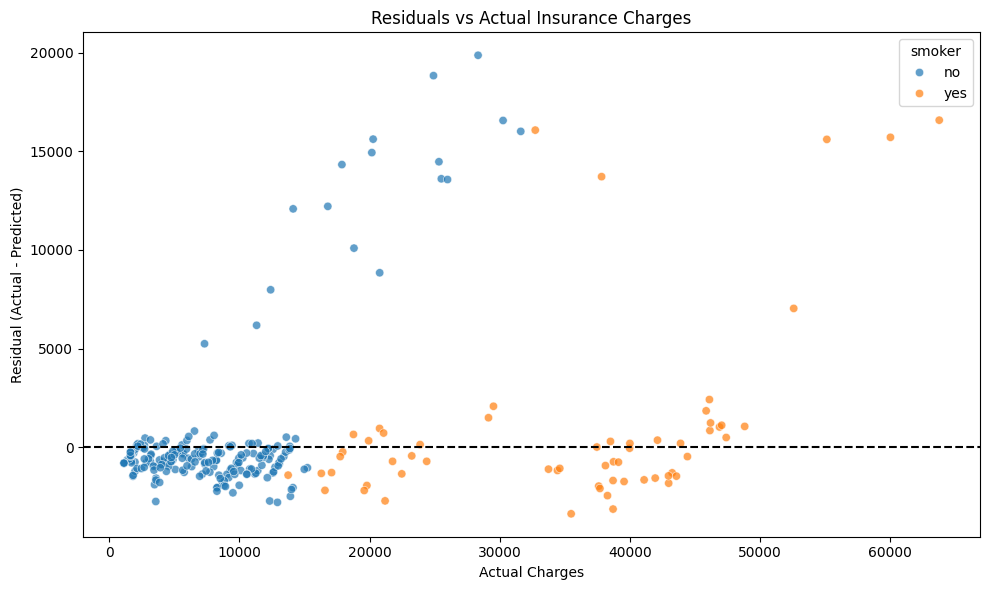

In [67]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=diagnostics_log,
    x="actual",
    y="residual",
    hue="smoker",
    alpha=0.7
)

plt.axhline(0, linestyle="--", color="black")

plt.title("Residuals vs Actual Insurance Charges")
plt.xlabel("Actual Charges")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [68]:
diagnostics_log["charge_range"] = pd.cut(
    diagnostics_log["actual"],
    bins=[0, 10000, 20000, 30000, 40000, float("inf")],
    labels=[
        "0-10k",
        "10k-20k",
        "20k-30k",
        "30k-40k",
        "40k+"
    ]
)

charge_error_analysis = (
    diagnostics_log
    .groupby("charge_range", observed=False)
    .agg(
        count=("actual", "count"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean")
    )
)

display(charge_error_analysis.round(2))

,count,actual_mean,predicted_mean,MAE,mean_residual
charge_range,,,,,
0-10k,142,"5,254.370","5,892.730",784.850,-638.360
10k-20k,66,"13,399.660","13,175.780","1,761.810",223.890
20k-30k,18,"23,823.760","17,199.660","7,282.380","6,624.100"
30k-40k,20,"36,663.530","34,641.980","4,246.940","2,021.550"
40k+,22,"46,922.780","44,376.130","3,429.820","2,546.640"


### Residual Analysis and Key Findings

The residual analysis indicates that the log-transformed Random Forest
performs reasonably well for most lower-charge observations.

However, prediction errors increase substantially for certain higher-charge
observations, particularly those within the 20,000–30,000 charge range.

The model tends to underestimate charges in the higher charge ranges,
suggesting that the available features do not fully capture the variability
in expensive insurance cases.

Although logarithmic target transformation improved overall MAE, it did
not eliminate systematic prediction errors across all charge ranges.

## 8. Final Model Selection and Training

Based on five-fold cross-validation, the Random Forest with a
log-transformed target achieved the lowest MAE among the evaluated
configurations.

The selected model uses TransformedTargetRegressor to apply log1p
during training and expm1 during prediction.

In [69]:
# Final selected model: Log-transformed Random Forest
final_model = TransformedTargetRegressor(
    regressor=tuning_model,
    func=np.log1p,
    inverse_func=np.expm1
)

# Fit on the complete training set
final_model.fit(X_train, y_train)

print("Final log-transformed Random Forest trained successfully.")

Final log-transformed Random Forest trained successfully.


## 9. Model Serialization

Save the complete fitted preprocessing and prediction pipeline so it can
be loaded and reused without retraining.

In [70]:
model_path = Path("/kaggle/working/insurance_cost_pipeline.joblib")

joblib.dump(final_model, model_path)

print(f"Model saved to: {model_path}")
print(f"File size: {model_path.stat().st_size / 1024:.2f} KB")

Model saved to: /kaggle/working/insurance_cost_pipeline.joblib
File size: 3609.01 KB


In [71]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Generate predictions using both models
original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

# Verify predictions match
import numpy as np

print(
    "Predictions match:",
    np.allclose(original_predictions, loaded_predictions)
)

Predictions match: True


## 10. Reusable Prediction Function

Create a function that accepts raw customer features and returns an
insurance charge prediction using the saved pipeline.

In [72]:
# Load the saved pipeline
# Using model without validation
loaded_model = joblib.load(model_path)

def predict_insurance_cost(
    age,
    sex,
    bmi,
    children,
    smoker,
    region
):
    customer = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    prediction = loaded_model.predict(customer)[0]

    return round(float(prediction), 2)

In [73]:
predicted_charge = predict_insurance_cost(
    age=35,
    sex="male",
    bmi=28.5,
    children=1,
    smoker="no",
    region="northwest"
)

print(f"Predicted insurance charge: {predicted_charge:,.2f}")

Predicted insurance charge: 5,529.97


In [74]:
# Using model with validation
loaded_model = joblib.load(model_path)

VALID_SEX = {"male", "female"}
VALID_SMOKER = {"yes", "no"}
VALID_REGIONS = {
    "northeast", "northwest", "southeast", "southwest"
}


def predict_insurance_cost(
    age,
    sex,
    bmi,
    children,
    smoker,
    region
):
    # Validate numeric inputs
    if not isinstance(age, (int, float)) or isinstance(age, bool):
        raise ValueError("Age must be numeric.")

    if not 0 < age <= 120:
        raise ValueError("Age must be between 1 and 120.")

    if not isinstance(bmi, (int, float)) or isinstance(bmi, bool):
        raise ValueError("BMI must be numeric.")

    if not 0 < bmi < 100:
        raise ValueError("BMI must be greater than 0 and below 100.")

    if (
        not isinstance(children, int)
        or isinstance(children, bool)
        or children < 0
    ):
        raise ValueError("Children must be a non-negative integer.")

    # Validate categorical inputs
    if not isinstance(sex, str) or sex.lower() not in VALID_SEX:
        raise ValueError("Sex must be 'male' or 'female'.")

    if not isinstance(smoker, str) or smoker.lower() not in VALID_SMOKER:
        raise ValueError("Smoker must be 'yes' or 'no'.")

    if not isinstance(region, str) or region.lower() not in VALID_REGIONS:
        raise ValueError(
            "Region must be northeast, northwest, southeast, or southwest."
        )

    customer = pd.DataFrame([{
        "age": age,
        "sex": sex.lower(),
        "bmi": bmi,
        "children": children,
        "smoker": smoker.lower(),
        "region": region.lower()
    }])

    prediction = loaded_model.predict(customer)[0]

    return round(float(prediction), 2)

In [75]:
# Invalid input: should raise ValueError

try:
    predict_insurance_cost(
        age=-5,
        sex="male",
        bmi=28.5,
        children=1,
        smoker="no",
        region="northwest"
    )
except ValueError as error:
    print("Validation works:", error)

Validation works: Age must be between 1 and 120.


In [76]:
import sklearn
import sys
print("Python & it's environment package versions:")
print("python", sys.version)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("joblib:", joblib.__version__)

Python & it's environment package versions:
python 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
scikit-learn: 1.6.1
pandas: 2.3.3
NumPy: 2.1.3
joblib: 1.6.0
